## 1. 라이브러리 임포트

데이터셋 로드에 필요한 라이브러리를 불러옵니다.
- `torch`: 텐서 연산
- `torchvision.datasets`: FashionMNIST 데이터셋 제공
- `torchvision.transforms`: 이미지를 텐서로 변환
- `numpy`: 배열 기반 수치 계산 (EDA 통계)
- `matplotlib`: 이미지 및 그래프 시각화 (EDA)
- `sys`: 실행 중인 Python 버전 확인

In [32]:
import sys

import torch
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# 실행 환경의 버전 확인 (팀원 간 환경 차이로 오류가 생겼을 때 원인 파악용)
print(f"Python      : {sys.version.split()[0]}")
print(f"torch       : {torch.__version__}")
print(f"torchvision : {torchvision.__version__}")
print(f"numpy       : {np.__version__}")
print(f"matplotlib  : {matplotlib.__version__}")

Python      : 3.12.14
torch       : 2.14.1+cu130
torchvision : 0.29.1+cu130
numpy       : 2.5.4
matplotlib  : 3.11.2


## 2. FashionMNIST 데이터셋 불러오기

FashionMNIST는 10개 의류 클래스로 구성된 28×28 흑백 이미지 데이터셋입니다.
- 학습 데이터: 60,000장
- 테스트 데이터: 10,000장

- 클래스 목록:
    - T-shirt/top
    - Trouser
    - Pullover
    - Dress
    - Coat
    - Sandal
    - Shirt
    - Sneaker
    - Bag
    - Ankle boot

EDA 결과를 해석하기 쉽도록, 이 단계에서는 `ToTensor()`만 적용합니다.
`ToTensor()`는 0~255 정수 픽셀을 255로 나눠 0.0~1.0 실수로 바꿉니다.
생성 모델 학습에 필요한 정규화는 이후 전처리 단계에서 별도로 적용합니다.

데이터는 레포 규칙(`data/README.md`)에 따라 레포 최상위의 `data/raw/`에 저장합니다.
노트북이 `eda/` 폴더에 있으므로 상대 경로 `../data/raw`를 사용합니다.

In [33]:
# 데이터셋을 저장할 경로 (없으면 자동 생성)
DATA_ROOT = '../data/raw'

# PIL 이미지(uint8, 0~255) → FloatTensor(0.0~1.0), shape: (채널=1, 높이=28, 너비=28)
eda_transform = transforms.ToTensor()

# 학습 데이터셋 (train=True) - 로컬에 없으면 다운로드
train_dataset = torchvision.datasets.FashionMNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=eda_transform
)

# 테스트 데이터셋 (train=False)
test_dataset = torchvision.datasets.FashionMNIST(
    root=DATA_ROOT,
    train=False,
    download=True,
    transform=eda_transform
)

## 3. 데이터셋 로드 결과 확인

데이터가 정상적으로 로드되었는지 간단히 확인합니다.
- 학습/테스트 데이터 개수
- 샘플 1개의 shape, 자료형, 픽셀 값 범위
- 클래스 인덱스와 클래스 이름의 매핑 (이후 EDA와 시각화에서 사용)

In [34]:
# 데이터 개수 확인
print(f"학습 데이터 개수  : {len(train_dataset):,}")
print(f"테스트 데이터 개수: {len(test_dataset):,}")

# 첫 번째 샘플로 변환 결과 확인
img, label = train_dataset[0]
print(f"\n이미지 shape : {tuple(img.shape)}")   # (1, 28, 28) 예상
print(f"이미지 dtype : {img.dtype}")            # torch.float32 예상
print(f"픽셀 값 범위 : [{img.min().item():.3f}, {img.max().item():.3f}]")  # 0~1 사이 예상
print(f"레이블       : {label} ({train_dataset.classes[label]})")

# 클래스 인덱스 → 클래스 이름 매핑
idx_to_class = {i: name for i, name in enumerate(train_dataset.classes)}
idx_to_class

학습 데이터 개수  : 60,000
테스트 데이터 개수: 10,000

이미지 shape : (1, 28, 28)
이미지 dtype : torch.float32
픽셀 값 범위 : [0.000, 1.000]
레이블       : 9 (Ankle boot)


{0: 'T-shirt/top',
 1: 'Trouser',
 2: 'Pullover',
 3: 'Dress',
 4: 'Coat',
 5: 'Sandal',
 6: 'Shirt',
 7: 'Sneaker',
 8: 'Bag',
 9: 'Ankle boot'}

## 4. 클래스(옷 종류)별 이미지 개수 확인

옷 종류마다 이미지가 몇 장씩 있는지 직접 세어 확인합니다.

### 방법
- 학습/테스트 데이터셋에서 `targets` 속성의 값을 꺼내, 값별로 개수를 셉니다.
- 이 값이 각 이미지의 클래스 번호인지는 결과로 확인합니다.
  - 값별 개수의 합계가 이미지 수(학습 60,000 / 테스트 10,000)와 같은가?
  - 값이 클래스 번호 범위(0~9) 안에 있는가?
- 결과는 표(정확한 숫자)와 막대그래프(한눈에 비교)로 확인합니다.
  - 학습과 테스트는 전체 규모가 달라서, 그래프를 두 개로 나눠 그립니다.
  - 그래프 안의 글자는 한글이 깨지지 않도록 영어로 표시합니다.

### 확인할 점
- 클래스마다 개수가 고르게 나뉘어 있는가?

No  Class          Train  Train %    Test  Test %
-------------------------------------------------
 0  T-shirt/top    6,000    10.0%   1,000   10.0%
 1  Trouser        6,000    10.0%   1,000   10.0%
 2  Pullover       6,000    10.0%   1,000   10.0%
 3  Dress          6,000    10.0%   1,000   10.0%
 4  Coat           6,000    10.0%   1,000   10.0%
 5  Sandal         6,000    10.0%   1,000   10.0%
 6  Shirt          6,000    10.0%   1,000   10.0%
 7  Sneaker        6,000    10.0%   1,000   10.0%
 8  Bag            6,000    10.0%   1,000   10.0%
 9  Ankle boot     6,000    10.0%   1,000   10.0%
-------------------------------------------------
    Total         60,000   100.0%  10,000  100.0%


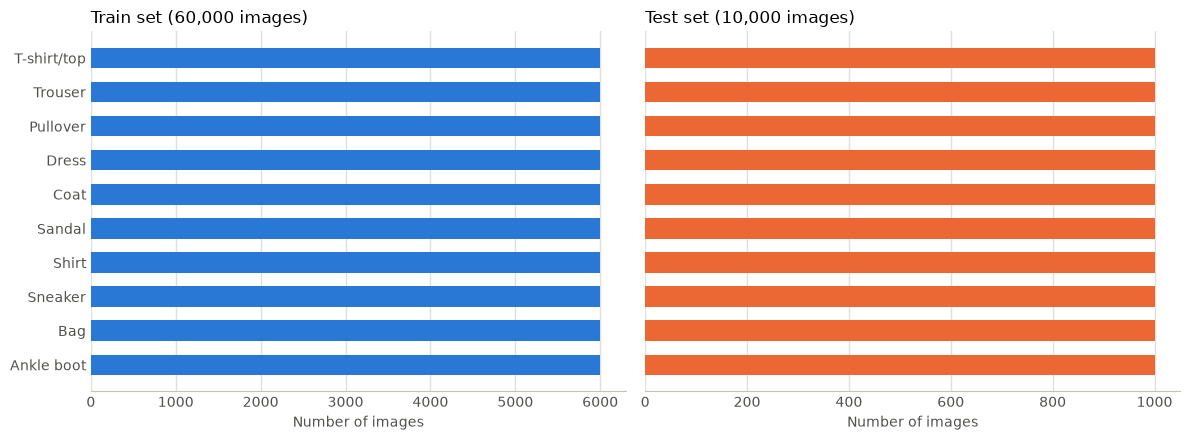

In [35]:
# 4-1. 학습/테스트 데이터셋의 targets 값 꺼내기
#  - 이미지를 한 장씩 불러오지 않고 targets 값만 한 번에 꺼냅니다.
#  - 이 값이 각 이미지의 클래스 번호인지는 아래 표의 결과(합계, 값 범위)로 확인합니다.
train_labels = train_dataset.targets.numpy()
test_labels = test_dataset.targets.numpy()

class_names = train_dataset.classes   # ['T-shirt/top', 'Trouser', ...]
num_classes = len(class_names)        # 10

# 4-2. 클래스별 개수 세기
#  - np.bincount: 0, 1, 2, ... 각 번호가 몇 번 나오는지 셉니다.
#  - minlength=num_classes: 개수가 0인 클래스가 있어도 결과 길이를 10으로 맞춥니다.
train_counts = np.bincount(train_labels, minlength=num_classes)
test_counts = np.bincount(test_labels, minlength=num_classes)

# 4-3. 표로 출력 (클래스별 개수 + 전체 대비 비율)
print(f"{'No':>2}  {'Class':<12} {'Train':>7} {'Train %':>8} {'Test':>7} {'Test %':>7}")
print("-" * 49)
for i, name in enumerate(class_names):
    train_ratio = train_counts[i] / train_counts.sum() * 100
    test_ratio = test_counts[i] / test_counts.sum() * 100
    print(f"{i:>2}  {name:<12} {train_counts[i]:>7,} {train_ratio:>7.1f}% "
          f"{test_counts[i]:>7,} {test_ratio:>6.1f}%")
print("-" * 49)
print(f"{'':>2}  {'Total':<12} {train_counts.sum():>7,} {'100.0%':>8} "
      f"{test_counts.sum():>7,} {'100.0%':>7}")

# 4-4. 막대그래프로 시각화
#  - 학습/테스트는 전체 개수 규모가 달라서(60,000 vs 10,000) 그래프를 두 개로 나눠 그립니다.
#  - 클래스 이름이 길어서 가로 막대그래프(barh)를 사용합니다.
#  - 그래프 안의 글자는 영어로 씁니다. (matplotlib 기본 글꼴은 한글이 깨져서 보이기 때문)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, counts, title, color in zip(
    axes,
    [train_counts, test_counts],
    [f"Train set ({train_counts.sum():,} images)", f"Test set ({test_counts.sum():,} images)"],
    ["#2a78d6", "#eb6834"],   # 학습: 파란색, 테스트: 주황색
):
    ax.barh(range(num_classes), counts, color=color, height=0.6)
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel("Number of images", color="#52514e")
    ax.grid(axis="x", color="#e1e0d9", linewidth=1)   # 옅은 세로 보조선
    ax.set_axisbelow(True)                            # 보조선을 막대 뒤로 보내기
    for side in ["top", "right", "left"]:             # 불필요한 테두리 제거
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", length=0)

axes[0].set_yticks(range(num_classes))
axes[0].set_yticklabels(class_names)
axes[0].invert_yaxis()   # 0번 클래스가 맨 위에 오도록 순서 뒤집기

plt.tight_layout()
plt.show()

### 결과
- 학습 데이터: 10개 클래스 모두 6,000장씩(각 10.0%)이고, 합계는 60,000장입니다.
- 테스트 데이터: 10개 클래스 모두 1,000장씩(각 10.0%)이고, 합계는 10,000장입니다.
- 막대그래프에서도 학습/테스트 모두 클래스마다 막대 길이가 같습니다.

### 해석
- `targets` 값이 각 이미지의 클래스 번호인가?
  - 값별 개수의 합계(학습 60,000 / 테스트 10,000)가 '3. 데이터셋 로드 결과 확인'의 실행 결과에서 확인한 이미지 수와 같습니다. 이미지마다 `targets` 값이 하나씩 있다는 뜻입니다.
  - 0~9번 개수를 모두 더한 값이 전체 합계와 같으므로, 0~9 밖의 값은 없습니다.
  - 두 기준을 모두 만족하므로, 이후 단계에서는 `targets` 값을 각 이미지의 클래스 번호로 사용합니다. 번호와 실제 이미지가 맞는지는 '5. 클래스별 샘플 이미지 확인'에서 이미지로 확인합니다.
- 클래스마다 개수가 고르게 나뉘어 있는가?
  - 학습/테스트 모두 모든 클래스의 개수가 같아, 클래스 간 개수 차이(불균형)가 없습니다.

## 5. 클래스별 샘플 이미지 확인

옷 종류마다 실제 이미지가 어떻게 생겼는지 눈으로 확인합니다.

### 방법
- '4. 클래스(옷 종류)별 이미지 개수 확인'에서 꺼낸 학습 데이터의 `targets` 값을 기준으로, 클래스마다 5장씩 무작위로 골라 10줄 × 5칸으로 보여줍니다.
- 랜덤 시드(`SEED = 42`)를 고정해서, 다시 실행하거나 팀원이 실행해도 같은 이미지가 나오도록 합니다.
- 데이터셋의 `data` 속성에 저장된 이미지를 흑백으로 표시합니다.
  - 모든 이미지의 밝기 기준을 같게 하기 위해 표시 범위를 0~255로 고정합니다.

### 확인할 점
- 옷 종류마다 어떻게 생겼는가?
- 서로 헷갈릴 만한 비슷한 종류가 있는가?
- 같은 종류 안에서도 모양이 얼마나 다양한가?

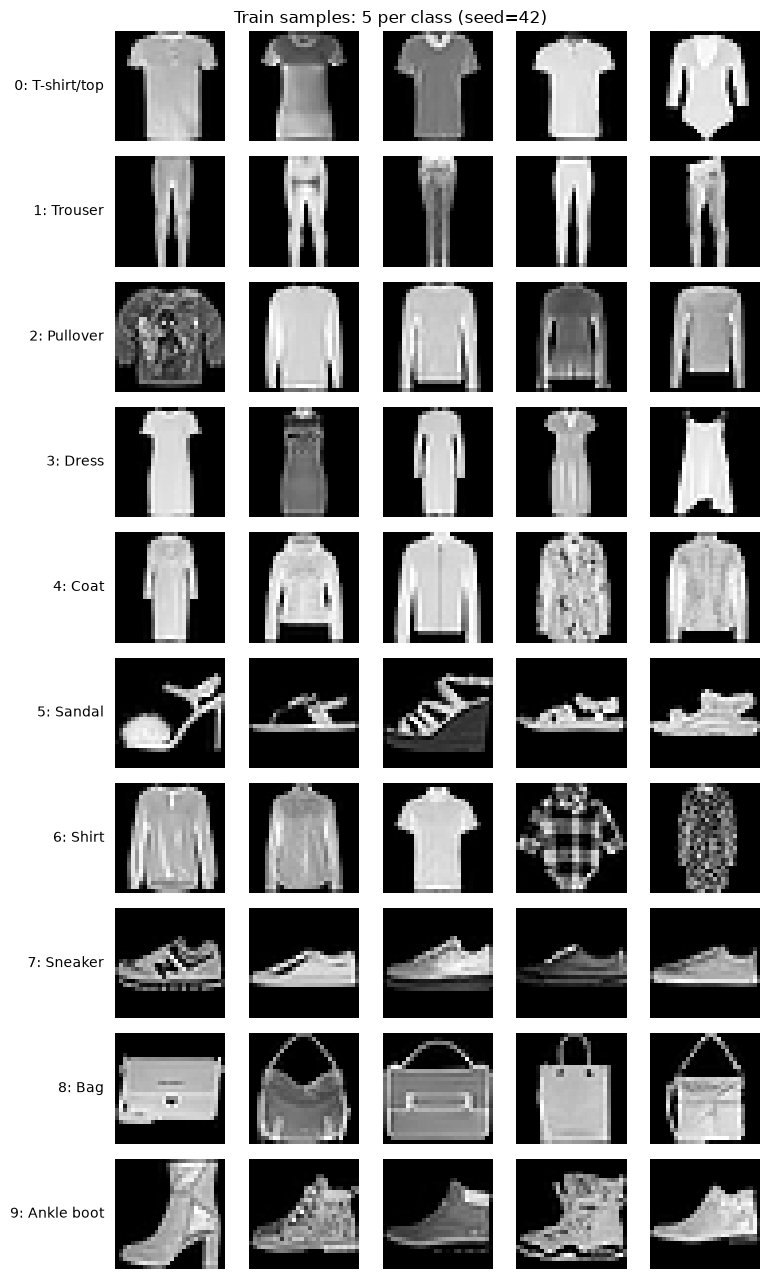

In [36]:
# 5-1. 설정값
N_SAMPLES_PER_CLASS = 5   # 클래스마다 보여줄 이미지 수
SEED = 42                 # 랜덤 시드: 실행할 때마다 같은 이미지가 뽑히도록 고정

rng = np.random.default_rng(SEED)

# 5-2. 그림판 만들기: 10줄(클래스) x 5칸(이미지)
fig, axes = plt.subplots(
    num_classes, N_SAMPLES_PER_CLASS,
    figsize=(N_SAMPLES_PER_CLASS * 1.3 + 1.5, num_classes * 1.3),
)

for class_idx, class_name in enumerate(class_names):
    # 5-3. 이 클래스에 속하는 이미지들의 위치(인덱스) 찾기
    #  - train_labels는 '4. 클래스(옷 종류)별 이미지 개수 확인'에서 꺼낸 학습 데이터의 targets 값입니다.
    class_indices = np.where(train_labels == class_idx)[0]

    # 5-4. 그중 N장을 중복 없이 무작위로 선택
    chosen = rng.choice(class_indices, size=N_SAMPLES_PER_CLASS, replace=False)

    for col, img_idx in enumerate(chosen):
        ax = axes[class_idx, col]

        # 5-5. data 속성에 저장된 이미지를 흑백으로 표시
        #  - vmin/vmax를 0~255로 고정해서 모든 이미지의 밝기 기준을 똑같이 맞춥니다.
        img = train_dataset.data[img_idx].numpy()
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)

        # 눈금과 테두리 제거 (이미지만 보이도록)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    # 5-6. 각 줄 맨 왼쪽에 클래스 번호와 이름 표시
    axes[class_idx, 0].set_ylabel(
        f"{class_idx}: {class_name}",
        rotation=0, ha="right", va="center", fontsize=10, labelpad=8,
    )

fig.suptitle(f"Train samples: {N_SAMPLES_PER_CLASS} per class (seed={SEED})", fontsize=12)
plt.tight_layout()
plt.show()

### 결과
클래스마다 5장씩만 본 결과이므로, 아래 내용은 이 샘플에서 관찰한 것입니다.
아래에서 'n번째'는 각 줄의 왼쪽부터 센 순서입니다.

- 옷 종류마다 어떻게 생겼는가?
  - 배경은 검은색이고, 물건은 배경보다 밝은 회색~흰색으로 표시됩니다.
  - 모든 이미지에 물건이 하나씩, 가운데에 크게 놓여 있습니다.
  - 옷(T-shirt/top, Trouser, Pullover, Dress, Coat, Shirt)과 Bag은 앞에서 본 모습입니다.
  - 신발(Sandal, Sneaker, Ankle boot)은 옆에서 본 모습이고, 15장 모두 앞코가 왼쪽을 향합니다.
- 서로 헷갈릴 만한 비슷한 종류가 있는가?
  - 긴팔 상의인 Pullover(2, 3, 5번째), Coat(3, 5번째), Shirt(1, 2번째)는 전체 윤곽이 서로 비슷합니다.
  - Shirt 3번째는 반팔이라 T-shirt/top(1~4번째)과 윤곽이 비슷합니다.
  - Coat 1번째는 길이가 길어 Dress 3번째와 윤곽이 비슷합니다.
- 같은 종류 안에서도 모양이 얼마나 다양한가?
  - 무늬: Pullover 1번째, Coat 4번째, Shirt 4, 5번째는 무늬가 있고, 같은 줄의 다른 이미지는 무늬가 거의 없습니다.
  - 밝기: Trouser 3번째, Dress 2번째, Sneaker 4번째는 같은 줄의 다른 이미지보다 어둡습니다.
  - 모양:
    - T-shirt/top: 1~4번째는 반팔이고, 5번째는 긴팔에 아랫단이 뾰족합니다.
    - Dress: 반팔(1, 4번째), 긴팔(3번째), 어깨끈 형태(5번째)로 소매 모양이 다릅니다.
    - Sandal: 굽이 높은 것(1번째), 밑창이 두꺼운 것(3번째), 납작한 것(2, 4, 5번째)이 섞여 있습니다.
    - Bag: 손잡이가 보이지 않는 것(1번째)과 손잡이나 끈이 달린 것(2~5번째)이 섞여 있습니다.
    - Ankle boot: 굽이 높은 것(1번째)과 굽이 낮은 것(2~5번째)이 섞여 있습니다.

### 해석
- 각 줄의 이미지가 왼쪽에 적힌 클래스 이름에 해당하는 물건으로 보입니다. '4. 클래스(옷 종류)별 이미지 개수 확인'에서 사용한 `targets` 값이 실제 이미지의 클래스 번호와 맞는다는 것을 눈으로 확인했습니다.
- 5장만 본 결과이므로, 위의 관찰이 데이터 전체에도 해당하는지는 이 셀만으로는 알 수 없습니다.

## 6. 이상치 확인

학습/테스트 데이터에 크기나 형식이 다른 이미지, 비어 있는 이미지 같은 이상치가 있는지 확인합니다.

### 목적
- 데이터는 사람이 만들고 정리하기 때문에, 실수로 이상한 이미지가 섞여 있을 수 있습니다.
- 학습 전에 빼야 할 이미지가 있는지 확인하고, 있으면 제거 대상으로 기록합니다.

### 방법
- 크기와 형식
  - 데이터셋의 `data` 속성은 이미지 전체를 하나의 배열로 묶어 저장합니다. 하나의 배열 안에 있는 이미지는 모두 같은 크기여야 하므로, 크기가 다른 이미지가 있는지는 배열의 shape로 확인합니다.
  - 학습/테스트 배열의 shape와 자료형(dtype)을 출력합니다.
- 값 범위: 학습/테스트 전체 픽셀의 최솟값과 최댓값을 출력합니다.
- 빈 이미지
  - 이미지마다 0(검은색)이 아닌 픽셀의 수를 셉니다. 이 값을 이미지 안에서 물건이 차지하는 크기로 봅니다.
  - 이 값이 0인 이미지, 즉 완전히 검은 이미지가 몇 장인지 학습/테스트 각각 출력합니다.
- 시각화
  - 그림 1: 0이 아닌 픽셀 수의 분포를 클래스별 박스 플롯으로 그립니다.
    - 박스는 가운데 50%의 이미지가 모인 범위이고, 박스 안의 선은 중앙값입니다.
    - 박스 끝에서 박스 길이의 1.5배보다 멀리 떨어진 이미지는 점으로 따로 표시됩니다(matplotlib 기본 설정).
    - 물건의 크기는 클래스마다 다를 수 있으므로, 전체가 아닌 클래스별로 비교합니다.
    - 학습/테스트를 두 그래프로 나란히 그리고, '4. 클래스(옷 종류)별 이미지 개수 확인'과 같은 방향(가로)과 색(학습 파랑, 테스트 주황)을 사용합니다.
  - 그림 2: 클래스마다 0이 아닌 픽셀 수가 가장 적은 이미지 3장을 학습/테스트 각각 보여 줍니다.
    - 10줄 × 6칸으로, 왼쪽 3칸은 학습, 오른쪽 3칸은 테스트 이미지입니다.
    - 0이 아닌 픽셀 수가 0보다 크더라도 거의 빈 이미지일 수 있으므로, 최종 판단은 이미지를 직접 보고 합니다.
  - 그림 3: 클래스마다 0이 아닌 픽셀 수가 가장 많은 이미지 3장을 그림 2와 같은 방식으로 보여 줍니다.
    - 0이 아닌 픽셀에는 아주 흐린 픽셀(값 1, 2 등)도 포함되므로, 값이 큰 이미지에는 물건이 큰 경우와 배경에 흐린 잡음이 있는 경우가 섞여 있을 수 있습니다.
    - 다른 그림과 같은 0~255 표시 범위로 그리기 때문에, 아주 흐린 잡음은 그림에서 검은색과 구별되지 않을 수 있습니다.
  - 그래프 안의 글자는 한글이 깨지지 않도록 영어로 표시합니다.

### 확인할 점
- 학습/테스트 모두 크기와 형식이 같은가?
- 완전히 빈 이미지가 있는가?
- 클래스별로 다른 이미지와 동떨어지게 작은 이미지가 있는가? 있다면 실제로 이상한 이미지인가?
- 0이 아닌 픽셀 수가 가장 많은 이미지는 실제로 물건이 화면을 크게 차지하는 이미지인가?

학습 이미지 : shape (60000, 28, 28), dtype uint8, 값 범위 [0, 255]
테스트 이미지 : shape (10000, 28, 28), dtype uint8, 값 범위 [0, 255]

빈 이미지 수            - 학습: 0장, 테스트: 0장
0이 아닌 픽셀 수 범위   - 학습: [54, 725], 테스트: [91, 746]


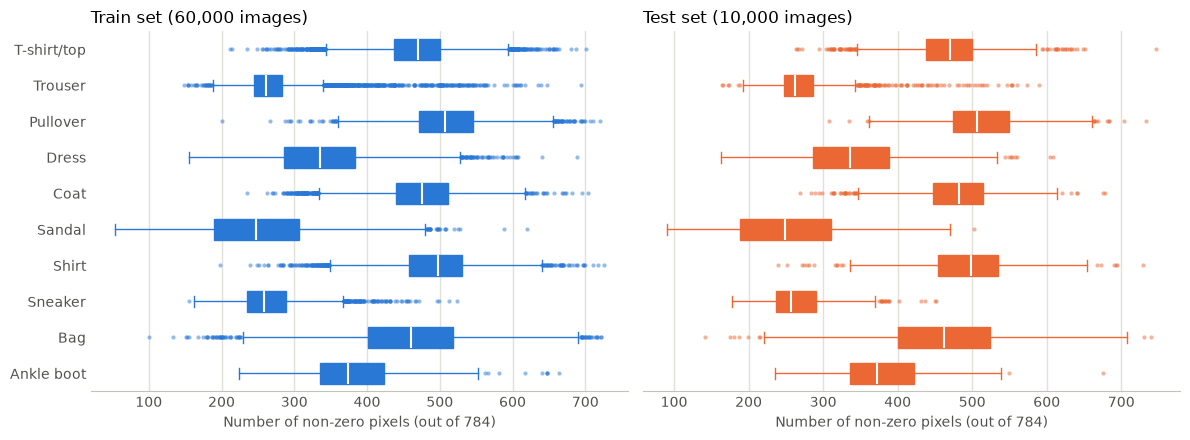

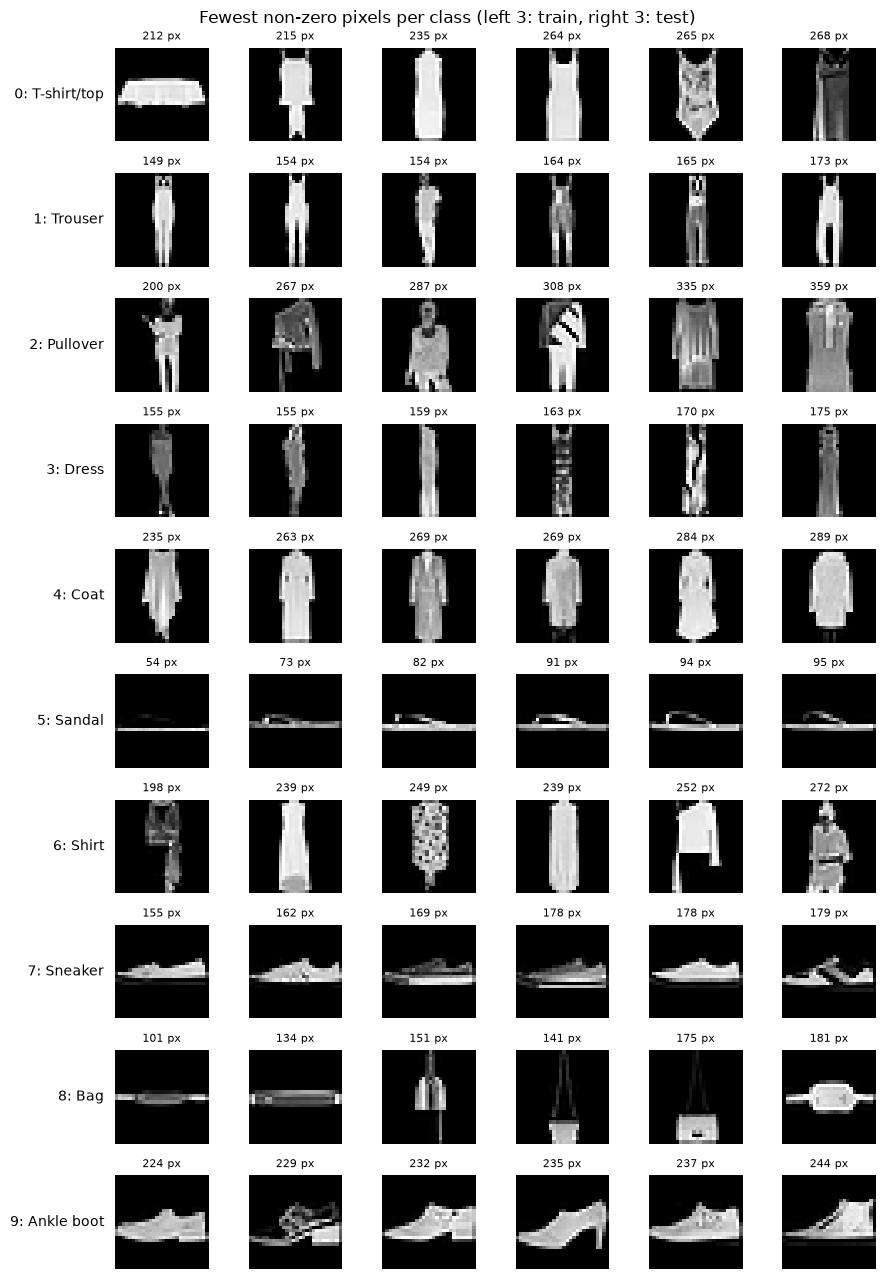

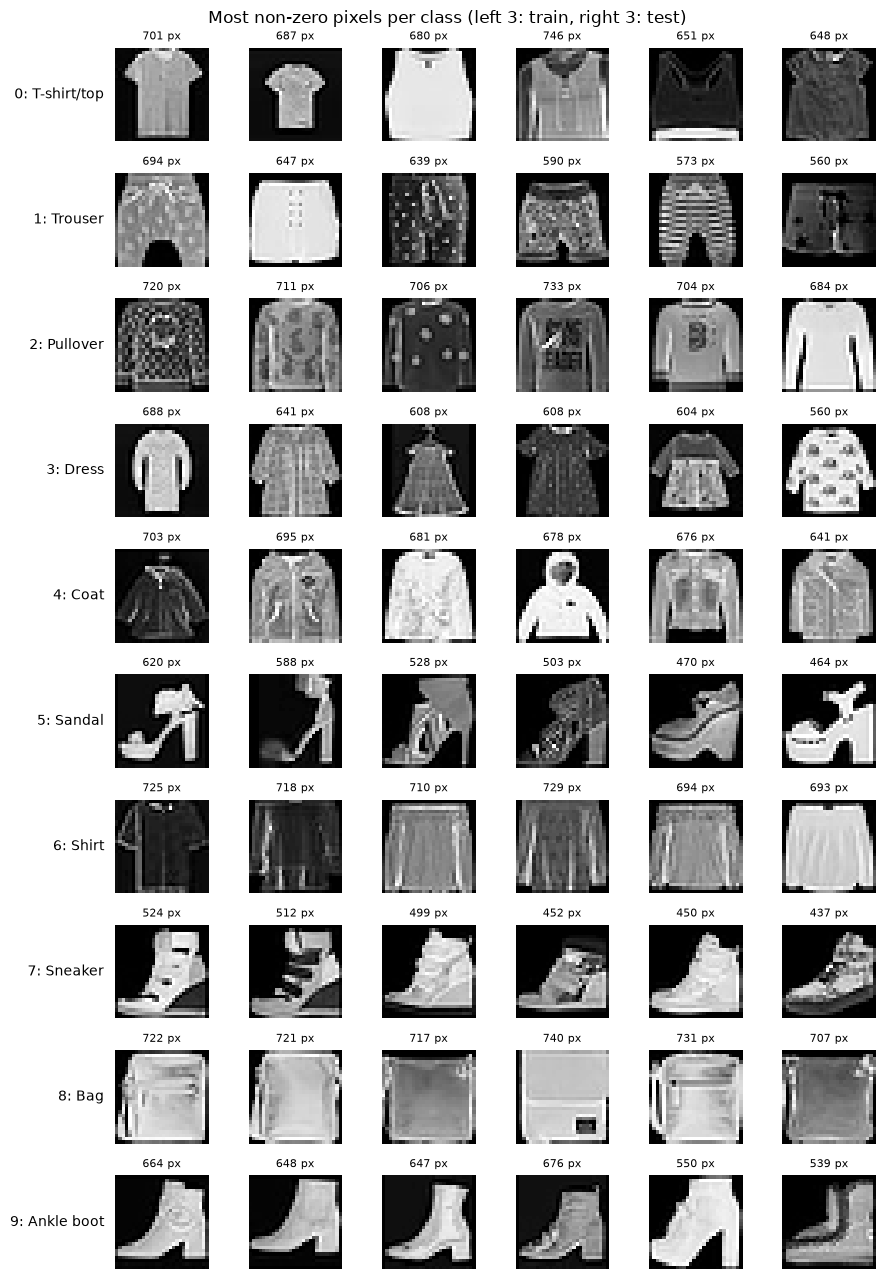

In [37]:
# 6-1. 학습/테스트 이미지 전체를 numpy 배열로 꺼내기
#  - data 속성: 데이터셋에 저장된 이미지 전체가 하나의 배열로 묶여 있습니다.
train_images = train_dataset.data.numpy()
test_images = test_dataset.data.numpy()

# 6-2. 크기·형식과 값 범위 출력
#  - shape: (이미지 수, 높이, 너비) → 하나의 배열이므로 모든 이미지의 높이·너비가 같습니다.
#  - min/max: 배열 전체에서 가장 작은 픽셀 값과 가장 큰 픽셀 값
for set_name, images in [("학습", train_images), ("테스트", test_images)]:
    print(f"{set_name} 이미지 : shape {images.shape}, dtype {images.dtype}, "
          f"값 범위 [{images.min()}, {images.max()}]")

# 6-3. 이미지마다 0(검은색)이 아닌 픽셀 수 세기
#  - images > 0        : 픽셀마다 0보다 크면 True, 아니면 False인 배열 (이미지 수, 28, 28)
#  - .sum(axis=(1, 2)) : 이미지 한 장 안에서 True의 개수를 셈 → 이미지마다 숫자 1개
train_nonzero = (train_images > 0).sum(axis=(1, 2))
test_nonzero = (test_images > 0).sum(axis=(1, 2))

# 6-4. 완전히 빈 이미지(0이 아닌 픽셀이 하나도 없는 이미지) 개수와 0이 아닌 픽셀 수의 범위
print(f"\n빈 이미지 수            - 학습: {(train_nonzero == 0).sum()}장, "
      f"테스트: {(test_nonzero == 0).sum()}장")
print(f"0이 아닌 픽셀 수 범위   - 학습: [{train_nonzero.min()}, {train_nonzero.max()}], "
      f"테스트: [{test_nonzero.min()}, {test_nonzero.max()}]")

# 6-5. 그림 1: 0이 아닌 픽셀 수의 분포를 클래스별 박스 플롯으로 그리기
#  - 학습/테스트를 두 그래프로 나란히 그립니다. (클래스 순서와 색은 '4. 클래스(옷 종류)별 이미지 개수 확인'과 같음)
#  - orientation="horizontal": 클래스 이름이 길어서 가로 방향으로 그립니다.
#  - 박스에서 멀리 떨어진 이미지는 점(flier)으로 따로 표시됩니다.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, nonzero, labels, title, color in zip(
    axes,
    [train_nonzero, test_nonzero],
    [train_labels, test_labels],
    [f"Train set ({len(train_nonzero):,} images)", f"Test set ({len(test_nonzero):,} images)"],
    ["#2a78d6", "#eb6834"],   # 학습: 파란색, 테스트: 주황색
):
    # 클래스별로 0이 아닌 픽셀 수만 모은 목록 (10개)
    per_class = [nonzero[labels == class_idx] for class_idx in range(num_classes)]

    ax.boxplot(
        per_class,
        positions=range(num_classes),
        orientation="horizontal",
        widths=0.6,
        patch_artist=True,                                     # 박스 안을 색으로 채우기
        boxprops=dict(facecolor=color, edgecolor=color),
        medianprops=dict(color="white", linewidth=1.5),        # 중앙값 선
        whiskerprops=dict(color=color),
        capprops=dict(color=color),
        flierprops=dict(marker="o", markersize=3, markerfacecolor=color,
                        markeredgecolor="none", alpha=0.5),    # 동떨어진 이미지 점
    )
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel("Number of non-zero pixels (out of 784)", color="#52514e")
    ax.grid(axis="x", color="#e1e0d9", linewidth=1)   # 옅은 세로 보조선
    ax.set_axisbelow(True)                            # 보조선을 박스 뒤로 보내기
    for side in ["top", "right", "left"]:             # 불필요한 테두리 제거
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", length=0)

axes[0].set_yticks(range(num_classes))
axes[0].set_yticklabels(class_names)
axes[0].invert_yaxis()   # 0번 클래스가 맨 위에 오도록 순서 뒤집기

plt.tight_layout()
plt.show()

# 6-6. 그림 2: 클래스마다 0이 아닌 픽셀 수가 가장 적은 이미지 3장 (왼쪽 3칸: 학습, 오른쪽 3칸: 테스트)
N_SMALLEST = 3   # 클래스마다 보여줄 이미지 수 (학습/테스트 각각)

fig, axes = plt.subplots(
    num_classes, N_SMALLEST * 2,
    figsize=(N_SMALLEST * 2 * 1.3 + 1.5, num_classes * 1.3),
)

for class_idx, class_name in enumerate(class_names):
    for set_idx, (images, labels, nonzero) in enumerate([
        (train_images, train_labels, train_nonzero),
        (test_images, test_labels, test_nonzero),
    ]):
        # 이 클래스 이미지들의 위치(인덱스)를 0이 아닌 픽셀 수가 적은 순서로 정렬해서 앞에서 N개 선택
        #  - kind="stable": 픽셀 수가 같을 때 원래 순서를 유지해서, 다시 실행해도 같은 이미지가 나오도록 함
        class_indices = np.where(labels == class_idx)[0]
        order = np.argsort(nonzero[class_indices], kind="stable")
        smallest = class_indices[order[:N_SMALLEST]]

        for k, img_idx in enumerate(smallest):
            ax = axes[class_idx, set_idx * N_SMALLEST + k]
            ax.imshow(images[img_idx], cmap="gray", vmin=0, vmax=255)   # 다른 섹션과 같은 0~255 표시 범위
            ax.set_title(f"{nonzero[img_idx]} px", fontsize=8)           # 이 이미지의 0이 아닌 픽셀 수

            # 눈금과 테두리 제거 (이미지만 보이도록)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)

    # 각 줄 맨 왼쪽에 클래스 번호와 이름 표시
    axes[class_idx, 0].set_ylabel(
        f"{class_idx}: {class_name}",
        rotation=0, ha="right", va="center", fontsize=10, labelpad=8,
    )

fig.suptitle(f"Fewest non-zero pixels per class (left {N_SMALLEST}: train, right {N_SMALLEST}: test)", fontsize=12)
plt.tight_layout()
plt.show()

# 6-7. 그림 3: 클래스마다 0이 아닌 픽셀 수가 가장 많은 이미지 3장 (왼쪽 3칸: 학습, 오른쪽 3칸: 테스트)
#  - 0이 아닌 픽셀에는 아주 흐린 픽셀(값 1, 2 등)도 포함되므로,
#    값이 큰 이미지가 실제로 물건이 큰 이미지인지 눈으로 확인합니다.
#  - 그림 2와 같은 방식이고, 정렬 순서만 반대(많은 순서)입니다.
N_LARGEST = 3   # 클래스마다 보여줄 이미지 수 (학습/테스트 각각)

fig, axes = plt.subplots(
    num_classes, N_LARGEST * 2,
    figsize=(N_LARGEST * 2 * 1.3 + 1.5, num_classes * 1.3),
)

for class_idx, class_name in enumerate(class_names):
    for set_idx, (images, labels, nonzero) in enumerate([
        (train_images, train_labels, train_nonzero),
        (test_images, test_labels, test_nonzero),
    ]):
        # 이 클래스 이미지들의 위치(인덱스)를 0이 아닌 픽셀 수가 많은 순서로 정렬해서 앞에서 N개 선택
        #  - -nonzero[...]   : 부호를 바꿔서 정렬하면 값이 큰 이미지가 앞으로 옵니다.
        #  - kind="stable"   : 픽셀 수가 같을 때 원래 순서를 유지해서, 다시 실행해도 같은 이미지가 나오도록 함
        class_indices = np.where(labels == class_idx)[0]
        order = np.argsort(-nonzero[class_indices], kind="stable")
        largest = class_indices[order[:N_LARGEST]]

        for k, img_idx in enumerate(largest):
            ax = axes[class_idx, set_idx * N_LARGEST + k]
            ax.imshow(images[img_idx], cmap="gray", vmin=0, vmax=255)   # 다른 섹션과 같은 0~255 표시 범위
            ax.set_title(f"{nonzero[img_idx]} px", fontsize=8)           # 이 이미지의 0이 아닌 픽셀 수

            # 눈금과 테두리 제거 (이미지만 보이도록)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)

    # 각 줄 맨 왼쪽에 클래스 번호와 이름 표시
    axes[class_idx, 0].set_ylabel(
        f"{class_idx}: {class_name}",
        rotation=0, ha="right", va="center", fontsize=10, labelpad=8,
    )

fig.suptitle(f"Most non-zero pixels per class (left {N_LARGEST}: train, right {N_LARGEST}: test)", fontsize=12)
plt.tight_layout()
plt.show()

### 결과
아래에서 'n번째 칸'은 그림 2, 3의 각 줄에서 왼쪽부터 센 순서입니다. 1~3번째 칸은 학습, 4~6번째 칸은 테스트 이미지입니다.

- 학습/테스트 모두 크기와 형식이 같은가?
  - 학습 (60000, 28, 28), 테스트 (10000, 28, 28)이고, 둘 다 자료형은 uint8, 값 범위는 [0, 255]입니다.
- 완전히 빈 이미지가 있는가?
  - 빈 이미지는 학습 0장, 테스트 0장입니다.
  - 0이 아닌 픽셀 수는 학습 54~725, 테스트 91~746입니다.
- 클래스별로 다른 이미지와 동떨어지게 작은 이미지가 있는가? 있다면 실제로 이상한 이미지인가?
  - 그림 1에서 박스의 위치가 클래스마다 다릅니다. Trouser, Sandal, Sneaker는 0이 아닌 픽셀 수가 적은 쪽에, T-shirt/top, Pullover, Coat, Shirt, Bag은 많은 쪽에 박스가 있습니다.
  - 학습과 테스트의 박스 위치는 클래스마다 비슷합니다.
  - 박스에서 떨어진 점은 대부분의 클래스에서 여러 개 찍혀 있습니다.
  - 그림 2(가장 적은 이미지)에서 눈에 띄는 이미지는 아래와 같습니다.
    - T-shirt/top 1번째 칸: 가운데에 납작한 가로 띠만 있어 티셔츠 모양으로 보이지 않습니다.
    - Sandal 1번째 칸(54 px): 얇은 가로줄과 아주 흐린 끈만 보여, 거의 빈 이미지에 가깝습니다.
    - Pullover 1, 3, 4번째 칸, Shirt 6번째 칸: 옷만이 아니라 머리나 다리가 함께 보여, 사람이 입고 있는 모습처럼 보입니다.
    - Ankle boot 4번째 칸: 발목을 덮는 부분이 없는 굽 높은 구두처럼 보입니다.
    - Shirt 5번째 칸: 어떤 옷인지 알아보기 어렵습니다.
    - T-shirt/top 3, 4, 6번째 칸, Pullover 5, 6번째 칸, Shirt 2, 4번째 칸: 길이가 긴 모양이라 Dress와 비슷해 보입니다.
- 0이 아닌 픽셀 수가 가장 많은 이미지는 실제로 물건이 화면을 크게 차지하는 이미지인가?
  - 그림 3의 이미지는 대부분 물건이 화면을 크게 채우고 있고, 잡음으로만 이루어진 이미지는 보이지 않았습니다.
  - 다만 T-shirt/top 2번째 칸(687 px)은 티셔츠 자체는 작게 찍혀 있고, 주변 배경이 완전한 검은색이 아니라 어두운 회색입니다. 이 이미지는 물건이 커서가 아니라 배경 때문에 픽셀 수가 크게 나왔습니다.
  - Sneaker 1, 2번째 칸은 발목까지 올라오는 높은 운동화라 Ankle boot와 비슷해 보입니다.
  
### 해석
- 학습/테스트 이미지는 모두 28×28, uint8, 0~255 범위로, 크기와 형식에는 이상이 없습니다.
- 완전히 빈 이미지는 없지만, 거의 빈 이미지(Sandal 1번째 칸, 54 px)는 있습니다.
- 0이 아닌 픽셀 수는 클래스마다 크게 다르므로, 이상치는 전체가 아니라 클래스별로 비교해야 합니다.
- 이 기준(0이 아닌 픽셀 수)으로는 학습과 테스트 데이터가 비슷하게 분포합니다.
- 박스 플롯에서 떨어진 점은 많았지만, 그중 가장 끝에 있는 이미지(그림 2, 3)도 대부분은 물건이 작거나 크게 찍힌 이미지로 보였습니다. 점으로 찍혔다고 해서 모두 이상한 이미지는 아닙니다.
- 아래 이미지는 이상치 후보로 기록만 하고, 데이터에서 빼지 않고 그대로 사용합니다. 빈 이미지나 잡음으로만 이루어진 이미지처럼 뚜렷한 이상치는 발견되지 않았기 때문입니다.
  - 거의 빈 이미지: Sandal 1번째 칸 (그림 2)
  - 사람이 입고 있는 모습으로 보이는 이미지: Pullover 1, 3, 4번째 칸, Shirt 6번째 칸 (그림 2)
  - 클래스 이름과 다른 물건처럼 보이는 이미지: T-shirt/top 1번째 칸, Ankle boot 4번째 칸 (그림 2)
  - 배경이 완전히 검지 않은 이미지: T-shirt/top 2번째 칸 (그림 3)
- Dress와 비슷해 보이는 상의, Ankle boot와 비슷해 보이는 Sneaker처럼 클래스 사이의 경계가 애매한 이미지도 있습니다. 이것은 잘못된 데이터라기보다, 클래스끼리 비슷하게 생긴 이미지가 섞여 있다는 관찰입니다.

### 한계
- 그림 2, 3에서는 클래스마다 0이 아닌 픽셀 수가 가장 적은/많은 이미지를 학습/테스트 각각 3장씩만 봤습니다. 그래서 위와 같은 이미지나 잡음이 섞인 이미지가 더 있을 가능성은 남아 있습니다.
- 그림을 0~255 표시 범위로 그렸기 때문에, 배경이 검은색으로 보여도 눈으로 구분하기 어려울 만큼 어두운 픽셀이 섞여 있을 수 있습니다. 그런 이미지가 더 있는지는 이번 방법으로는 확인하지 못했습니다.
- 0이 아닌 픽셀 수는 물건이 클 때뿐 아니라 배경이 완전히 검지 않을 때도 커집니다(T-shirt/top 2번째 칸). 그래서 이 값만으로 물건의 크기를 정확히 알 수는 없습니다.
- 이상한 이미지인지는 눈으로 판단한 것이라, 사람마다 다르게 볼 수 있습니다.

## 7. 클래스별 평균 이미지 확인

클래스마다 학습 이미지 전체를 평균 낸 이미지를 만들어, 각 클래스의 대표 모양을 확인합니다.

### 목적
- '5. 클래스별 샘플 이미지 확인'의 관찰은 클래스마다 5장만 본 결과라서, 데이터 전체에도 해당하는지 알 수 없었습니다.
- 클래스의 모든 이미지를 평균 내면 그 클래스의 전체적인 모양을 이미지 한 장으로 볼 수 있습니다. 이것으로 샘플 5장에서 본 관찰을 데이터 전체 기준으로 다시 확인합니다.

### 방법
- '4. 클래스(옷 종류)별 이미지 개수 확인'에서 꺼낸 학습 데이터의 `targets` 값으로 클래스별 이미지를 모읍니다.
- 같은 픽셀 위치끼리 값을 더해 이미지 수로 나눠, 클래스마다 평균 이미지 1장을 만듭니다.
  - 여러 이미지에서 공통으로 밝은 위치는 평균에서도 밝게 남고, 이미지마다 다른 위치는 중간 밝기로 흐려집니다.
- '5. 클래스별 샘플 이미지 확인'과 같은 기준으로 비교할 수 있도록 데이터셋의 `data` 속성에 저장된 이미지를 사용하고, 표시 범위를 0~255로 고정합니다.
- 10개 클래스의 평균 이미지를 2줄 × 5칸으로 나란히 그립니다.

### 확인할 점
- 클래스마다 평균 이미지가 또렷한 모양으로 나오는가, 흐리게 퍼지는가?
- '5. 클래스별 샘플 이미지 확인'에서 윤곽이 비슷하다고 본 클래스는 평균 이미지에서도 비슷한가?
  - Pullover, Coat, Shirt
  - Shirt와 T-shirt/top
  - Coat와 Dress
- '5. 클래스별 샘플 이미지 확인'에서 본 신발의 방향(앞코가 왼쪽)이 평균 이미지에서도 유지되는가?

학습 이미지 배열 shape : (60000, 28, 28)
학습 이미지 배열 dtype : uint8
평균 이미지 배열 shape : (10, 28, 28)


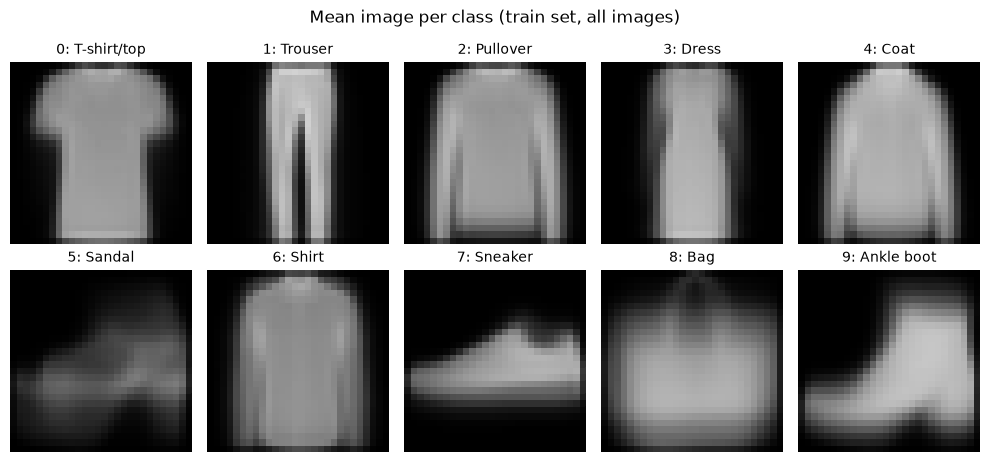

In [38]:
# 7-1. 학습 이미지 전체를 numpy 배열로 꺼내기
#  - data 속성: 데이터셋에 저장된 이미지 ('5. 클래스별 샘플 이미지 확인'에서 사용한 것과 같음)
#  - 배열의 크기(shape)와 자료형(dtype)은 아래 출력으로 확인합니다.
train_images = train_dataset.data.numpy()
print(f"학습 이미지 배열 shape : {train_images.shape}")   # (이미지 수, 높이, 너비)
print(f"학습 이미지 배열 dtype : {train_images.dtype}")

# 7-2. 클래스별 평균 이미지 계산
#  - train_labels == class_idx : 해당 클래스의 이미지 위치만 True로 표시
#  - train_images[...]         : 해당 클래스의 이미지만 골라내기
#  - .mean(axis=0)             : 골라낸 이미지들을 겹쳐서, 같은 픽셀 위치끼리 평균 → 이미지 1장
#  - np.stack                  : 클래스별 평균 이미지 10장을 하나의 배열로 묶기
mean_images = np.stack([
    train_images[train_labels == class_idx].mean(axis=0)
    for class_idx in range(num_classes)
])
print(f"평균 이미지 배열 shape : {mean_images.shape}")   # (클래스 수, 높이, 너비)

# 7-3. 평균 이미지 10장을 2줄 x 5칸으로 그리기
#  - '5. 클래스별 샘플 이미지 확인'과 같은 기준으로 비교하기 위해 표시 범위를 0~255로 고정합니다.
fig, axes = plt.subplots(2, 5, figsize=(10, 4.8))

for class_idx, ax in enumerate(axes.flat):   # axes.flat: 2x5 칸을 왼쪽 위부터 차례대로 하나씩 꺼냄
    ax.imshow(mean_images[class_idx], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{class_idx}: {class_names[class_idx]}", fontsize=10)

    # 눈금과 테두리 제거 (이미지만 보이도록)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle("Mean image per class (train set, all images)", fontsize=12)
plt.tight_layout()
plt.show()

### 결과
- 출력된 배열 크기
  - 학습 이미지 배열은 (60000, 28, 28), 자료형은 uint8입니다. 학습 이미지 60,000장이 모두 28×28 크기이고, 0~255 정수 형식으로 저장되어 있습니다.
  - 평균 이미지 배열은 (10, 28, 28)로, 클래스마다 28×28 평균 이미지가 1장씩 만들어졌습니다.
- 클래스마다 평균 이미지가 또렷한 모양으로 나오는가, 흐리게 퍼지는가?
  - T-shirt/top, Trouser, Pullover, Dress, Coat, Sneaker, Ankle boot는 평균 이미지만 보고도 어떤 물건인지 알아볼 수 있을 만큼 윤곽이 분명합니다.
    - 특히 Trouser는 두 다리 사이의 빈 공간까지 뚜렷하게 보입니다.
  - 나머지 세 클래스는 상대적으로 흐립니다.
    - Sandal: 10개 중 가장 어둡고, 윤곽이 넓게 퍼져 있습니다.
    - Bag: 아래쪽 사각형 몸통은 보이지만 위쪽은 흐리게 퍼져 있어, 손잡이 모양이 뚜렷하지 않습니다.
    - Shirt: 긴팔 상의 모양은 보이지만, Pullover, Coat보다 조금 어둡고 소매 경계가 덜 또렷합니다.
- '5. 클래스별 샘플 이미지 확인'에서 윤곽이 비슷하다고 본 클래스는 평균 이미지에서도 비슷한가?
  - Pullover, Coat, Shirt: 셋 모두 몸통 양옆으로 긴 소매가 아래까지 내려오는, 서로 비슷한 윤곽입니다.
  - Shirt와 T-shirt/top: T-shirt/top은 반팔, Shirt는 긴팔 윤곽으로 나와 서로 다르게 보입니다.
  - Coat와 Dress: Coat는 긴 소매가 있는 넓은 윤곽, Dress는 소매 부분이 흐리게만 보이는 좁고 긴 윤곽으로 서로 다르게 보입니다.
- '5. 클래스별 샘플 이미지 확인'에서 본 신발의 방향(앞코가 왼쪽)이 평균 이미지에서도 유지되는가?
  - Sneaker와 Ankle boot는 앞부분이 왼쪽, 발목·뒤꿈치 쪽이 오른쪽에 있는 모양으로 나옵니다.
  - Sandal은 흐려서 확실하지 않지만, 밝은 부분이 오른쪽으로 높게 올라가 있어 다른 신발과 같은 방향으로 보입니다.

### 해석
- 학습/테스트 이미지 전체의 크기와 형식 점검은 '6. 이상치 확인'에서 다룹니다. 이 섹션의 배열 크기 출력은 평균 이미지 계산에 사용한 배열을 확인하는 용도입니다.
- Pullover, Coat, Shirt는 데이터 전체 기준으로도 윤곽이 비슷합니다. 샘플 5장에서 본 관찰이 평균 이미지에서도 같게 나왔습니다.
- Shirt와 T-shirt/top, Coat와 Dress는 평균 이미지에서는 서로 다르게 보입니다. '5. 클래스별 샘플 이미지 확인'에서 비슷하다고 본 사례(Shirt 3번째, Coat 1번째)는 각 클래스의 평균 모양과는 다릅니다.
- 평균 이미지가 흐리다는 것은, 같은 위치에서 밝은 이미지와 어두운 이미지가 섞여 있다는 뜻입니다. Sandal과 Bag이 흐리게 나온 것은 '5. 클래스별 샘플 이미지 확인'에서 Sandal(굽 높이, 밑창)과 Bag(손잡이 유무)의 모양이 제각각이었던 관찰과 같은 방향입니다.
- 신발이 앞코가 왼쪽을 향하는 방향으로 놓여 있다는 점은 Sneaker와 Ankle boot에서 데이터 전체 기준으로도 확인됩니다. Sandal은 평균 이미지가 흐려서 이 결과만으로는 확실하지 않습니다.

## 8. 학습/테스트 밝기 비교

학습/테스트 이미지의 밝기가 비슷한지 클래스별로 비교합니다.

### 목적
- 생성 모델은 학습 데이터만 보고 배우지만, 생성 성능은 테스트 데이터를 기준으로 확인합니다.
- 학습과 테스트 이미지의 밝기가 다르면, 모델이 학습 데이터를 잘 따라 만들어도 테스트와 비교할 때 차이가 생겨 평가 결과가 실제 성능과 다르게 나올 수 있습니다.
- '6. 이상치 확인'에서는 물건의 크기(0이 아닌 픽셀 수)만 학습/테스트를 비교했고, 밝기는 비교하지 않았습니다.
- 이 결과로 테스트 데이터를 평가 기준으로 그대로 써도 되는지 판단합니다.

### 방법
- 이미지마다 물건 부분의 평균 밝기를 계산합니다.
  - 물건 부분은 '6. 이상치 확인'과 같이 0(검은색)이 아닌 픽셀로 봅니다.
  - 검은 배경까지 포함해 평균을 내면 물건이 작은 이미지가 어둡게 나와 크기와 밝기가 섞이므로, 물건 부분만 평균을 냅니다.
  - 배경 픽셀은 0이라 합에 영향을 주지 않으므로, 이미지 전체 픽셀 값의 합을 0이 아닌 픽셀 수로 나누면 물건 부분의 평균 밝기가 됩니다.
- 표: 클래스별로 학습/테스트의 밝기 중앙값과 그 차이(테스트 − 학습)를 출력합니다.
  - 평균 대신 중앙값을 쓰는 이유: 동떨어진 값의 영향을 덜 받습니다.
- 그림: 클래스마다 밝기 분포를 학습/테스트 겹쳐 그립니다(2줄 × 5칸, 칸마다 한 클래스).
  - 가로축은 밝기(0~255)를 8 단위 구간으로 나눈 것이고, 세로축은 그 클래스 이미지 중 해당 밝기 구간에 속하는 이미지의 비율(%)입니다.
  - 학습은 클래스당 6,000장, 테스트는 클래스당 1,000장으로 개수가 달라서, 개수 대신 비율로 맞춰 비교합니다.
  - 학습은 색칠한 면(파랑), 테스트는 선(주황)으로 그립니다. 두 모양이 겹칠수록 학습과 테스트의 밝기 분포가 비슷하다는 뜻입니다.
  - 10칸 모두 같은 밝기 구간과 가로축 범위를 사용합니다.
- 통계 검정은 하지 않고, 숫자와 그림으로 비교합니다.

### 확인할 점
- 학습과 테스트의 밝기 분포가 클래스마다 비슷한가?
- 같은 클래스 안에서 밝기가 얼마나 다양한가?

No  Class          Train    Test    Diff
----------------------------------------
 0  T-shirt/top    148.3   149.7    +1.4
 1  Trouser        170.0   168.9    -1.1
 2  Pullover       159.5   154.0    -5.5
 3  Dress          162.9   163.8    +0.9
 4  Coat           175.1   174.2    -0.9
 5  Sandal         104.5   103.7    -0.8
 6  Shirt          138.6   137.6    -1.0
 7  Sneaker        127.1   127.2    +0.1
 8  Bag            159.1   159.4    +0.3
 9  Ankle boot     162.2   162.4    +0.2
----------------------------------------
    All            150.7   149.7    -1.0


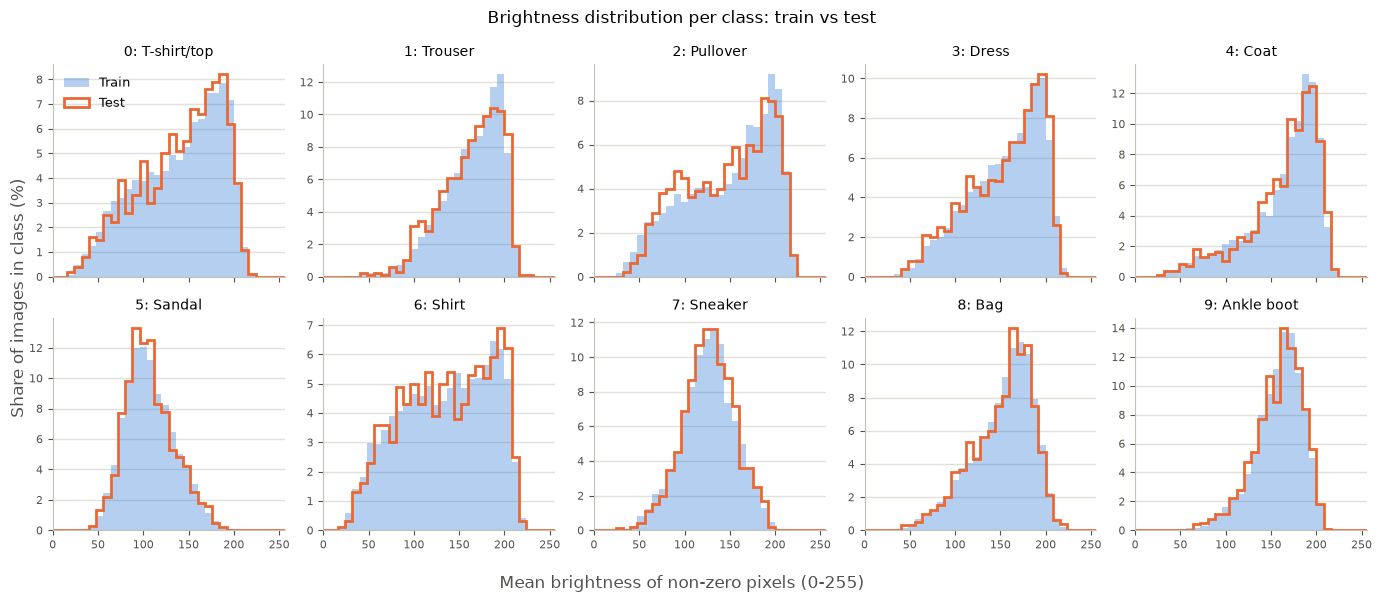

In [39]:
# 8-1. 이미지마다 물건 부분(0이 아닌 픽셀)의 평균 밝기 계산
#  - train_images, test_images     : '6. 이상치 확인'에서 만든 이미지 배열 (이미지 수, 28, 28)
#  - train_nonzero, test_nonzero   : '6. 이상치 확인'에서 센 이미지마다의 0이 아닌 픽셀 수
#  - images.sum(axis=(1, 2))       : 이미지 한 장의 픽셀 값을 모두 더함 (배경은 0이라 더해도 그대로)
#  - ÷ 0이 아닌 픽셀 수            : 물건 부분 픽셀 값의 평균 = 물건 부분의 평균 밝기 (0~255)
#  - '6. 이상치 확인'에서 빈 이미지가 0장이었으므로 0으로 나누는 경우는 없습니다.
train_brightness = train_images.sum(axis=(1, 2)) / train_nonzero
test_brightness = test_images.sum(axis=(1, 2)) / test_nonzero

# 8-2. 표로 출력: 클래스별 밝기 중앙값 (학습, 테스트, 차이 = 테스트 - 학습)
#  - 중앙값을 표에 보이는 자릿수(소수 첫째 자리)로 먼저 반올림한 뒤 차이를 계산합니다.
#    → 표에 보이는 두 값을 직접 빼면 Diff와 같은 값이 나옵니다.
print(f"{'No':>2}  {'Class':<12} {'Train':>7} {'Test':>7} {'Diff':>7}")
print("-" * 40)
for i, name in enumerate(class_names):
    train_median = round(float(np.median(train_brightness[train_labels == i])), 1)
    test_median = round(float(np.median(test_brightness[test_labels == i])), 1)
    print(f"{i:>2}  {name:<12} {train_median:>7.1f} {test_median:>7.1f} {test_median - train_median:>+7.1f}")
print("-" * 40)
train_all = round(float(np.median(train_brightness)), 1)
test_all = round(float(np.median(test_brightness)), 1)
print(f"{'':>2}  {'All':<12} {train_all:>7.1f} {test_all:>7.1f} {test_all - train_all:>+7.1f}")

# 8-3. 그림: 클래스마다 밝기 분포를 학습/테스트 겹쳐 그리기 (2줄 x 5칸, 칸마다 한 클래스)
#  - 가로축: 밝기(0~255)를 8 단위 구간으로 나눔 → 10칸 모두 같은 구간 사용
#  - 세로축: 그 클래스 이미지 중 해당 밝기 구간에 속하는 이미지의 비율(%)
#    (학습은 클래스당 6,000장, 테스트는 1,000장으로 개수가 달라서 비율로 맞춤)
#  - 학습: 색칠한 면(파랑), 테스트: 선(주황) → 두 모양이 겹칠수록 분포가 비슷함
BINS = np.arange(0, 256 + 8, 8)   # 구간 경계: 0, 8, 16, ..., 256 → 구간 32개

fig, axes = plt.subplots(2, 5, figsize=(14, 6), sharex=True)

for class_idx, ax in enumerate(axes.flat):   # axes.flat: 2x5 칸을 왼쪽 위부터 차례대로 하나씩 꺼냄
    train_vals = train_brightness[train_labels == class_idx]
    test_vals = test_brightness[test_labels == class_idx]

    # weights: 이미지 한 장마다 (100 / 이미지 수)를 더함 → 막대 높이가 개수가 아니라 비율(%)이 됨
    ax.hist(train_vals, bins=BINS, weights=np.full(len(train_vals), 100 / len(train_vals)),
            histtype="stepfilled", color="#2a78d6", alpha=0.35, label="Train")   # 학습: 색칠한 면
    ax.hist(test_vals, bins=BINS, weights=np.full(len(test_vals), 100 / len(test_vals)),
            histtype="step", color="#eb6834", linewidth=2, label="Test")         # 테스트: 선

    ax.set_title(f"{class_idx}: {class_names[class_idx]}", fontsize=10)
    ax.set_xlim(0, 256)                               # 밝기 전체 범위 (마지막 구간 248~256까지 보이도록)
    ax.grid(axis="y", color="#e1e0d9", linewidth=1)   # 옅은 가로 보조선
    ax.set_axisbelow(True)                            # 보조선을 그래프 뒤로 보내기
    for side in ["top", "right"]:                     # 불필요한 테두리 제거
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=8)

axes.flat[0].legend(frameon=False, fontsize=9)   # 범례는 첫 번째 칸에만 한 번 표시
fig.supxlabel("Mean brightness of non-zero pixels (0-255)", color="#52514e")
fig.supylabel("Share of images in class (%)", color="#52514e")
fig.suptitle("Brightness distribution per class: train vs test", fontsize=12)
plt.tight_layout()
plt.show()

### 결과
- 학습과 테스트의 밝기 분포가 클래스마다 비슷한가?
  - 표에서 클래스별 밝기 중앙값의 차이(테스트 − 학습)는 Pullover(−5.5)를 빼면 모두 −1.1 ~ +1.4 사이입니다.
  - 전체 중앙값은 학습 150.7, 테스트 149.7로 1.0 차이입니다.
  - 그림에서도 10개 클래스 모두 학습(면)과 테스트(선)의 모양이 대부분 겹칩니다.
  - 차이가 가장 큰 Pullover도 두 모양의 전체적인 형태는 비슷하고, 테스트 쪽이 어두운 구간(약 80~110)에 조금 더 많습니다.
  - 테스트 선이 학습보다 들쭉날쭉한 것은, 테스트 이미지 수(클래스당 1,000장)가 학습(클래스당 6,000장)보다 적기 때문으로 보입니다.
- 같은 클래스 안에서 밝기가 얼마나 다양한가?
  - 클래스마다 밝기 중앙값이 다릅니다. 학습 기준으로 Sandal(104.5)이 가장 어둡고, Coat(175.1)가 가장 밝습니다.
  - Shirt, T-shirt/top, Pullover는 가장 높은 막대가 약 7~9%로 낮고 넓게 퍼져 있어, 같은 클래스 안에서 밝기가 다양합니다.
  - Coat, Sandal, Ankle boot는 가장 높은 막대가 약 13~14%로, 밝기가 상대적으로 한 곳에 모여 있습니다.
  - 대부분의 클래스에서 어두운 쪽으로 길게 이어진 꼬리가 있어, 같은 클래스 안에 어두운 이미지가 섞여 있습니다. '5. 클래스별 샘플 이미지 확인'에서 같은 줄의 다른 이미지보다 어두운 이미지가 있었던 관찰과 같은 방향입니다.

### 해석
- 물건 부분의 밝기 기준으로, 학습과 테스트는 클래스마다 비슷하게 분포합니다.
- '6. 이상치 확인'의 크기(0이 아닌 픽셀 수) 비교 결과와 함께 보면, 테스트 데이터를 생성 결과 평가의 기준으로 그대로 사용해도 된다고 판단합니다.
- Pullover의 중앙값 차이(−5.5)는 다른 클래스보다 크지만, 밝기 범위(0~255)의 약 2% 정도이고 분포 모양도 비슷합니다. 다만 평가 단계에서 Pullover 결과를 볼 때는 이 차이를 함께 고려합니다.
- Shirt, T-shirt/top, Pullover처럼 클래스 안에서 밝기가 다양한 클래스는, 생성 결과의 밝기도 한쪽으로 몰리지 않고 다양하게 나오는지 볼 필요가 있습니다.

### 한계
- 통계 검정 없이 숫자와 그림으로 비교했기 때문에, 차이가 의미 있는 수준인지는 수치로 판단하지 않았습니다.
- 0이 아닌 픽셀을 모두 물건으로 봤기 때문에, 아주 흐린 픽셀이 섞인 이미지는 물건의 밝기가 실제보다 조금 낮게 계산될 수 있습니다.
- 이미지마다 밝기를 평균 하나로 줄여서 봤기 때문에, 무늬처럼 이미지 안에서 밝기가 어떻게 배치되는지는 반영되지 않습니다.

## 9. EDA 정리

지금까지의 EDA에서 확인한 내용과, 이를 바탕으로 정한 사항을 정리합니다.

### 확인한 내용
- 데이터 구성 ('3. 데이터셋 로드 결과 확인', '6. 이상치 확인')
  - 학습 데이터 60,000장, 테스트 데이터 10,000장입니다.
  - 학습/테스트 이미지 모두 28×28 크기의 흑백 이미지이고, uint8(0~255) 형식으로 저장되어 있습니다.
- 라벨 ('4. 클래스(옷 종류)별 이미지 개수 확인', '5. 클래스별 샘플 이미지 확인')
  - `targets` 값은 이미지마다 하나씩 있고 0~9 범위 안에 있으며, 샘플 이미지로 확인한 범위에서 실제 이미지의 클래스와 맞습니다.
  - 학습은 클래스마다 6,000장, 테스트는 클래스마다 1,000장으로, 모든 클래스의 개수가 같습니다.
- 생김새 ('5. 클래스별 샘플 이미지 확인', '7. 클래스별 평균 이미지 확인')
  - 대부분의 이미지는 검은 배경 위에 물건 하나가 가운데에 크게 놓여 있습니다. 옷과 Bag은 앞에서 본 모습, 신발은 옆에서 본 모습입니다.
  - Pullover, Coat, Shirt는 평균 이미지에서도 윤곽이 서로 비슷합니다.
  - Sneaker와 Ankle boot는 샘플과 평균 이미지 모두에서 앞코가 왼쪽을 향합니다.
  - Sandal, Bag, Shirt는 평균 이미지가 상대적으로 흐립니다. Sandal과 Bag은 샘플에서도 모양이 제각각이었습니다.
  - Shirt·T-shirt/top·Dress, Sneaker·Ankle boot처럼 클래스 사이의 경계가 애매한 이미지가 섞여 있습니다.
- 이상치 ('6. 이상치 확인')
  - 완전히 빈 이미지는 학습/테스트 모두 없습니다.
  - 0이 아닌 픽셀 수가 가장 적은/많은 이미지 중에는 거의 빈 이미지, 사람이 입고 있는 모습, 클래스 이름과 다른 물건처럼 보이는 이미지, 배경이 완전히 검지 않은 이미지가 일부 있습니다.
  - 잡음으로만 이루어진 이미지는 보이지 않았습니다.
  - 0이 아닌 픽셀 수 기준으로, 학습과 테스트의 분포는 클래스마다 비슷합니다.
- 밝기 ('8. 학습/테스트 밝기 비교')
  - 물건 부분의 평균 밝기 중앙값은 학습 150.7, 테스트 149.7입니다. 클래스별 차이는 Pullover(−5.5)를 빼면 모두 −1.1 ~ +1.4 사이이고, 분포 모양도 대부분 겹칩니다.
  - Shirt, T-shirt/top, Pullover는 같은 클래스 안에서 밝기가 넓게 퍼져 있습니다.

### 결정 사항
- 크기 조정은 하지 않습니다. 모든 이미지가 이미 28×28로 같습니다.
- 클래스 불균형 처리는 하지 않습니다. 모든 클래스의 개수가 같습니다.
- `targets` 값을 각 이미지의 클래스 번호로 사용합니다.
- 이상치 후보는 기록만 하고 데이터에서 빼지 않습니다. 빈 이미지나 잡음으로만 이루어진 이미지처럼 뚜렷한 이상치가 없었습니다.
- 테스트 데이터를 생성 결과 평가의 기준으로 그대로 사용합니다. 크기(0이 아닌 픽셀 수)와 밝기 모두 학습 데이터와 분포가 비슷합니다.

### 이후 단계에서 볼 점
- 생성 결과를 평가할 때
  - Pullover, Coat, Shirt처럼 서로 비슷한 클래스가 구분되게 생성되는지 확인합니다.
  - Sandal, Bag처럼 클래스 안의 모양이 다양한 클래스에서, 한 가지 모양만 반복해서 생성하지 않는지 확인합니다.
  - Shirt, T-shirt/top, Pullover처럼 클래스 안의 밝기가 다양한 클래스에서, 생성 결과의 밝기가 한쪽으로 몰리지 않는지 확인합니다.
  - Pullover는 학습/테스트의 밝기 중앙값 차이(−5.5)가 다른 클래스보다 크다는 점을 함께 고려합니다.
- 데이터 증강을 사용하는 경우
  - 신발의 앞코가 왼쪽을 향하고 있으므로, 좌우 반전은 데이터에 거의 없는 방향의 신발을 만들 수 있습니다.
  - 물건이 화면을 크게 차지하는 이미지가 많아, 자르기나 이동은 물건의 일부를 잘라낼 수 있습니다.

### 한계
- 이상치는 클래스마다 0이 아닌 픽셀 수가 가장 적은/많은 이미지를 학습/테스트 각각 3장씩만 눈으로 확인했습니다.
- 모양은 정상이지만 라벨이 틀린 이미지는 이번에 사용한 방법으로는 찾기 어렵습니다.
- 중복 이미지는 확인하지 않았습니다.
- 학습/테스트 비교(크기, 밝기)는 통계 검정 없이 숫자와 그림으로 판단했습니다.
- 샘플 이미지, 평균 이미지, 이상치에 대한 관찰은 눈으로 판단한 것이라 사람마다 다르게 볼 수 있습니다.